# Data processing

## Summary: Data Processing & Data Quality Audit 
(Duplicates, Missing Values, and `"unknown"` Counts)
1. Read `bank-additional-full.csv` with `sep=";"`.
2. Drop exact duplicate rows (`12` duplicates dropped: `41,188 -> 41,176` rows).
3. Map target `y`: `'no' -> 0`, `'yes' -> 1`.
4. Split `pdays` (`999` = never contacted before) into `previously_contacted` (`0/1`) and `pdays_clean` (`999 -> 0`), then drop `pdays`.
5. **Final Shape:** `(41176, 22)`.

## Step 1: Data info

In [1]:
import pandas as pd
import numpy as np
df = pd.read_csv("bank-additional-full.csv", sep=";")

In [2]:
print(df.head())
print(df.shape)

   age        job  marital    education  default housing loan    contact  \
0   56  housemaid  married     basic.4y       no      no   no  telephone   
1   57   services  married  high.school  unknown      no   no  telephone   
2   37   services  married  high.school       no     yes   no  telephone   
3   40     admin.  married     basic.6y       no      no   no  telephone   
4   56   services  married  high.school       no      no  yes  telephone   

  month day_of_week  ...  campaign  pdays  previous     poutcome emp.var.rate  \
0   may         mon  ...         1    999         0  nonexistent          1.1   
1   may         mon  ...         1    999         0  nonexistent          1.1   
2   may         mon  ...         1    999         0  nonexistent          1.1   
3   may         mon  ...         1    999         0  nonexistent          1.1   
4   may         mon  ...         1    999         0  nonexistent          1.1   

   cons.price.idx  cons.conf.idx  euribor3m  nr.employed

In [3]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  object 
 2   marital         41188 non-null  object 
 3   education       41188 non-null  object 
 4   default         41188 non-null  object 
 5   housing         41188 non-null  object 
 6   loan            41188 non-null  object 
 7   contact         41188 non-null  object 
 8   month           41188 non-null  object 
 9   day_of_week     41188 non-null  object 
 10  duration        41188 non-null  int64  
 11  campaign        41188 non-null  int64  
 12  pdays           41188 non-null  int64  
 13  previous        41188 non-null  int64  
 14  poutcome        41188 non-null  object 
 15  emp.var.rate    41188 non-null  float64
 16  cons.price.idx  41188 non-null  float64
 17  cons.conf.idx   41188 non-null 

From this info, there are no null values. However, there exists "unknown" category.
Then check Categorical Values.

In [4]:
for col in df.select_dtypes(include="object").columns:
    print("\n", col)
    print(df[col].value_counts())


 job
job
admin.           10422
blue-collar       9254
technician        6743
services          3969
management        2924
retired           1720
entrepreneur      1456
self-employed     1421
housemaid         1060
unemployed        1014
student            875
unknown            330
Name: count, dtype: int64

 marital
marital
married     24928
single      11568
divorced     4612
unknown        80
Name: count, dtype: int64

 education
education
university.degree      12168
high.school             9515
basic.9y                6045
professional.course     5243
basic.4y                4176
basic.6y                2292
unknown                 1731
illiterate                18
Name: count, dtype: int64

 default
default
no         32588
unknown     8597
yes            3
Name: count, dtype: int64

 housing
housing
yes        21576
no         18622
unknown      990
Name: count, dtype: int64

 loan
loan
no         33950
yes         6248
unknown      990
Name: count, dtype: int64

 contact
con

In [5]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 12


In [6]:
#Only 12 duplicate rows, delete them.
df = df.drop_duplicates().copy()
print("Shape after removing duplicates:", df.shape)

Shape after removing duplicates: (41176, 21)


In [7]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
age,41176.0,40.023800,10.420680,17.000,32.000,38.000,47.000,98.000
duration,41176.0,258.315815,259.305321,0.000,102.000,180.000,319.000,4918.000
campaign,41176.0,2.567879,2.770318,1.000,1.000,2.000,3.000,56.000
pdays,41176.0,962.464810,186.937102,0.000,999.000,999.000,999.000,999.000
previous,41176.0,0.173013,0.494964,0.000,0.000,0.000,0.000,7.000
emp.var.rate,41176.0,0.081922,1.570883,-3.400,-1.800,1.100,1.400,1.400
cons.price.idx,41176.0,93.575720,0.578839,92.201,93.075,93.749,93.994,94.767
cons.conf.idx,41176.0,-40.502863,4.627860,-50.800,-42.700,-41.800,-36.400,-26.900
euribor3m,41176.0,3.621293,1.734437,0.634,1.344,4.857,4.961,5.045
nr.employed,41176.0,5167.034870,72.251364,4963.600,5099.100,5191.000,5228.100,5228.100


## Step 2: Analysis based on checked info

In [8]:
print(df["y"].value_counts())
print(df["y"].value_counts(normalize=True))

y
no     36537
yes     4639
Name: count, dtype: int64
y
no     0.887337
yes    0.112663
Name: proportion, dtype: float64


In [9]:
target_distribution = (
    df["y"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

print(target_distribution)

y
no     88.73
yes    11.27
Name: proportion, dtype: float64


In [10]:
df["y"] = df["y"].map({
    "no": 0,
    "yes": 1
})

print(df["y"].value_counts())

y
0    36537
1     4639
Name: count, dtype: int64


0 = no subscription
1 = subscribed

In [11]:
df["previously_contacted"] = (df["pdays"] != 999).astype(int)

df["pdays_clean"] = np.where(
    df["pdays"] == 999,
    0,
    df["pdays"]
)

df = df.drop(columns=["pdays"])

Check again.

In [12]:
print("Final shape:", df.shape)

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:")
print(df.duplicated().sum())

print("\nTarget distribution:")
print(df["y"].value_counts())
print(df["y"].value_counts(normalize=True))

print("\nData types:")
print(df.dtypes)

Final shape: (41176, 22)

Missing values:
age                     0
job                     0
marital                 0
education               0
default                 0
housing                 0
loan                    0
contact                 0
month                   0
day_of_week             0
duration                0
campaign                0
previous                0
poutcome                0
emp.var.rate            0
cons.price.idx          0
cons.conf.idx           0
euribor3m               0
nr.employed             0
y                       0
previously_contacted    0
pdays_clean             0
dtype: int64

Duplicate rows:
0

Target distribution:
y
0    36537
1     4639
Name: count, dtype: int64
y
0    0.887337
1    0.112663
Name: proportion, dtype: float64

Data types:
age                       int64
job                      object
marital                  object
education                object
default                  object
housing                  object
loan          

### Random seed

In [14]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import StandardScaler

RANDOM_STATE = 42          # one seed for every random step: split, CV folds, models
np.random.seed(RANDOM_STATE)
pd.set_option("display.max_columns", 60)

### Encode categorical features (one-hot)

In [15]:
TARGET = "y"
CATEGORICAL_COLS = ["job", "marital", "education", "default", "housing", "loan",
                    "contact", "month", "day_of_week", "poutcome"]
NUMERIC_COLS = ["age", "duration", "campaign", "pdays_clean", "previous",
                "emp.var.rate", "cons.price.idx", "cons.conf.idx", "euribor3m", "nr.employed"]
BINARY_COLS = ["previously_contacted"]          # already 0/1, no encoding or scaling needed

# every cleaned column must belong to exactly one group
assert set(CATEGORICAL_COLS + NUMERIC_COLS + BINARY_COLS + [TARGET]) == set(df.columns)

df_model = pd.get_dummies(df, columns=CATEGORICAL_COLS, drop_first=True, dtype=int)
print("Shape after one-hot encoding:", df_model.shape)
df_model.head()

Shape after one-hot encoding: (41176, 55)


,age,duration,campaign,previous,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y,previously_contacted,pdays_clean,job_blue-collar,job_entrepreneur,job_housemaid,job_management,job_retired,job_self-employed,job_services,job_student,job_technician,job_unemployed,job_unknown,marital_married,marital_single,marital_unknown,education_basic.6y,education_basic.9y,education_high.school,education_illiterate,education_professional.course,education_university.degree,education_unknown,default_unknown,default_yes,housing_unknown,housing_yes,loan_unknown,loan_yes,contact_telephone,month_aug,month_dec,month_jul,month_jun,month_mar,month_may,month_nov,month_oct,month_sep,day_of_week_mon,day_of_week_thu,day_of_week_tue,day_of_week_wed,poutcome_nonexistent,poutcome_success
0,56,261,1,0,1.1,93.994,-36.4,4.857,5191.0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,1,0,0,0,1,0,0,0,1,0
1,57,149,1,0,1.1,93.994,-36.4,4.857,5191.0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0,0,1,0,0,0,0,1,0,0,0,0,0,1,0,0,0,0,0,1,0,0,0,1,0,0,0,1,0
2,37,226,1,0,1.1,93.994,-36.4,4.857,5191.0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0,0,1,0,0,0,0,0,0,0,1,0,0,1,0,0,0,0,0,1,0,0,0,1,0,0,0,1,0
3,40,151,1,0,1.1,93.994,-36.4,4.857,5191.0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,1,0,0,0,1,0,0,0,1,0
4,56,307,1,0,1.1,93.994,-36.4,4.857,5191.0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,1,0,0,0,1,0,0,0,1,0


### Train / test split

In [17]:
X = df_model.drop(columns=[TARGET])
y = df_model[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

print("Train:", X_train.shape, "  Test:", X_test.shape)
print(f"Subscription rate  train: {y_train.mean():.4f}   test: {y_test.mean():.4f}")

Train: (32940, 54)   Test: (8236, 54)
Subscription rate  train: 0.1127   test: 0.1127


### Feature sets with / without duration

In [18]:
featurewithduration = list(X_train.columns)
featurenoduration = [c for c in featurewithduration if c != "duration"]

print(len(featurewithduration), "features with duration |", len(featurenoduration), "features without duration")


54 features with duration | 53 features without duration


# Exploratory Data Analysis (EDA)
**Objective:** Perform a standalone Exploratory Data Analysis (EDA) on the UCI Bank Marketing dataset (`bank-additional-full.csv`, 41,188 raw rows) strictly following the group's data processing pipeline, without training any models, splitting, scaling, or one-hot encoding.

## 1. EDA Setup

In [13]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.patches import Patch
from matplotlib.lines import Line2D

plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.edgecolor'] = '#333333'
plt.rcParams['axes.linewidth'] = 0.8

COLOR_NO = '#4C72B0'
COLOR_YES = '#DD8452'
COLOR_MAIN = '#2B5C8F'
COLOR_WARN = '#C44E52'
BASE_RATE = df['y'].mean() * 100

In [14]:
# Audit 'unknown' string values across categorical variables
df_raw = pd.read_csv('bank-additional-full.csv', sep=';')
cat_cols = df.select_dtypes(include=['object']).columns.tolist()
unk_summary = []
for col in cat_cols:
    unk_n = int((df[col] == 'unknown').sum())
    unk_pct = unk_n / len(df) * 100
    raw_unk_n = int((df_raw[col] == 'unknown').sum())
    unk_rate = df.loc[df[col] == 'unknown', 'y'].mean() * 100 if unk_n > 0 else np.nan
    unk_summary.append({
        'column': col,
        'unknown_count_dedup': unk_n,
        'unknown_pct_dedup': round(unk_pct, 2),
        'unknown_count_raw': raw_unk_n,
        'unknown_sub_rate_%': round(unk_rate, 2) if not np.isnan(unk_rate) else None,
        'small_n_flag (<1000)': (0 < unk_n < 1000)
    })
unk_audit_df = pd.DataFrame(unk_summary).sort_values(by='unknown_count_dedup', ascending=False)
print(unk_audit_df.to_string(index=False))


     column  unknown_count_dedup  unknown_pct_dedup  unknown_count_raw  unknown_sub_rate_%  small_n_flag (<1000)
    default                 8596              20.88               8597                5.15                 False
  education                 1730               4.20               1731               14.51                 False
    housing                  990               2.40                990               10.81                  True
       loan                  990               2.40                990               10.81                  True
        job                  330               0.80                330               11.21                  True
    marital                   80               0.19                 80               15.00                  True
    contact                    0               0.00                  0                 NaN                 False
      month                    0               0.00                  0                 NaN      

## 2. Target Distribution
(`fig1_target_distribution.png`)

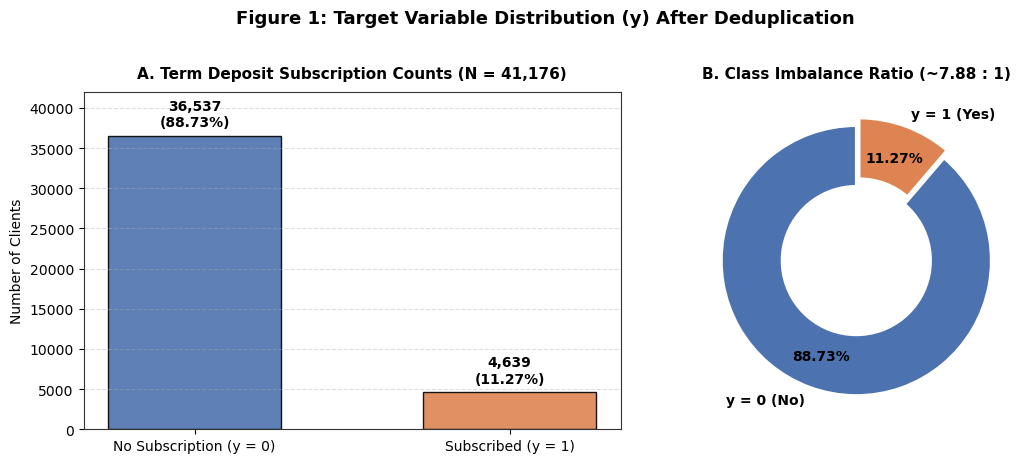

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), gridspec_kw={'width_ratios': [1.2, 1]})
y_counts = df['y'].value_counts().sort_index()
y_pcts = y_counts / len(df) * 100
labels = ['No Subscription (y = 0)', 'Subscribed (y = 1)']
colors = [COLOR_NO, COLOR_YES]

bars = axes[0].bar(labels, y_counts.values, color=colors, width=0.55, edgecolor='black', alpha=0.9)
axes[0].set_title('A. Term Deposit Subscription Counts (N = 41,176)', fontsize=11, fontweight='bold', pad=10)
axes[0].set_ylabel('Number of Clients', fontsize=10)
axes[0].set_ylim(0, 42000)
axes[0].grid(axis='y', linestyle='--', alpha=0.4)
for bar, cnt, pct in zip(bars, y_counts.values, y_pcts.values):
    axes[0].text(bar.get_x() + bar.get_width()/2, cnt + 800,
                 f'{cnt:,}\n({pct:.2f}%)', ha='center', va='bottom', fontsize=10, fontweight='bold')

axes[1].pie(
    y_counts.values, labels=['y = 0 (No)', 'y = 1 (Yes)'],
    autopct='%1.2f%%', startangle=90, colors=colors,
    pctdistance=0.75, explode=(0, 0.06),
    textprops={'fontsize': 10, 'fontweight': 'bold'},
    wedgeprops={'width': 0.45, 'edgecolor': 'white', 'linewidth': 2}
)
axes[1].set_title('B. Class Imbalance Ratio (~7.88 : 1)', fontsize=11, fontweight='bold', pad=10)
plt.suptitle('Figure 1: Target Variable Distribution (y) After Deduplication', fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('fig1_target_distribution.png', dpi=200, bbox_inches='tight')
plt.show()


## 3. Distributions of Numeric Variables 
(`fig2_numeric_distributions.png`)

                        count     mean     std      min      25%      50%      75%      max     IQR
age                   41176.0    40.02   10.42    17.00    32.00    38.00    47.00    98.00   15.00
duration              41176.0   258.32  259.31     0.00   102.00   180.00   319.00  4918.00  217.00
campaign              41176.0     2.57    2.77     1.00     1.00     2.00     3.00    56.00    2.00
previous              41176.0     0.17    0.49     0.00     0.00     0.00     0.00     7.00    0.00
previously_contacted  41176.0     0.04    0.19     0.00     0.00     0.00     0.00     1.00    0.00
pdays_clean           41176.0     0.22    1.35     0.00     0.00     0.00     0.00    27.00    0.00
emp.var.rate          41176.0     0.08    1.57    -3.40    -1.80     1.10     1.40     1.40    3.20
cons.price.idx        41176.0    93.58    0.58    92.20    93.08    93.75    93.99    94.77    0.92
cons.conf.idx         41176.0   -40.50    4.63   -50.80   -42.70   -41.80   -36.40   -26.90    6.30


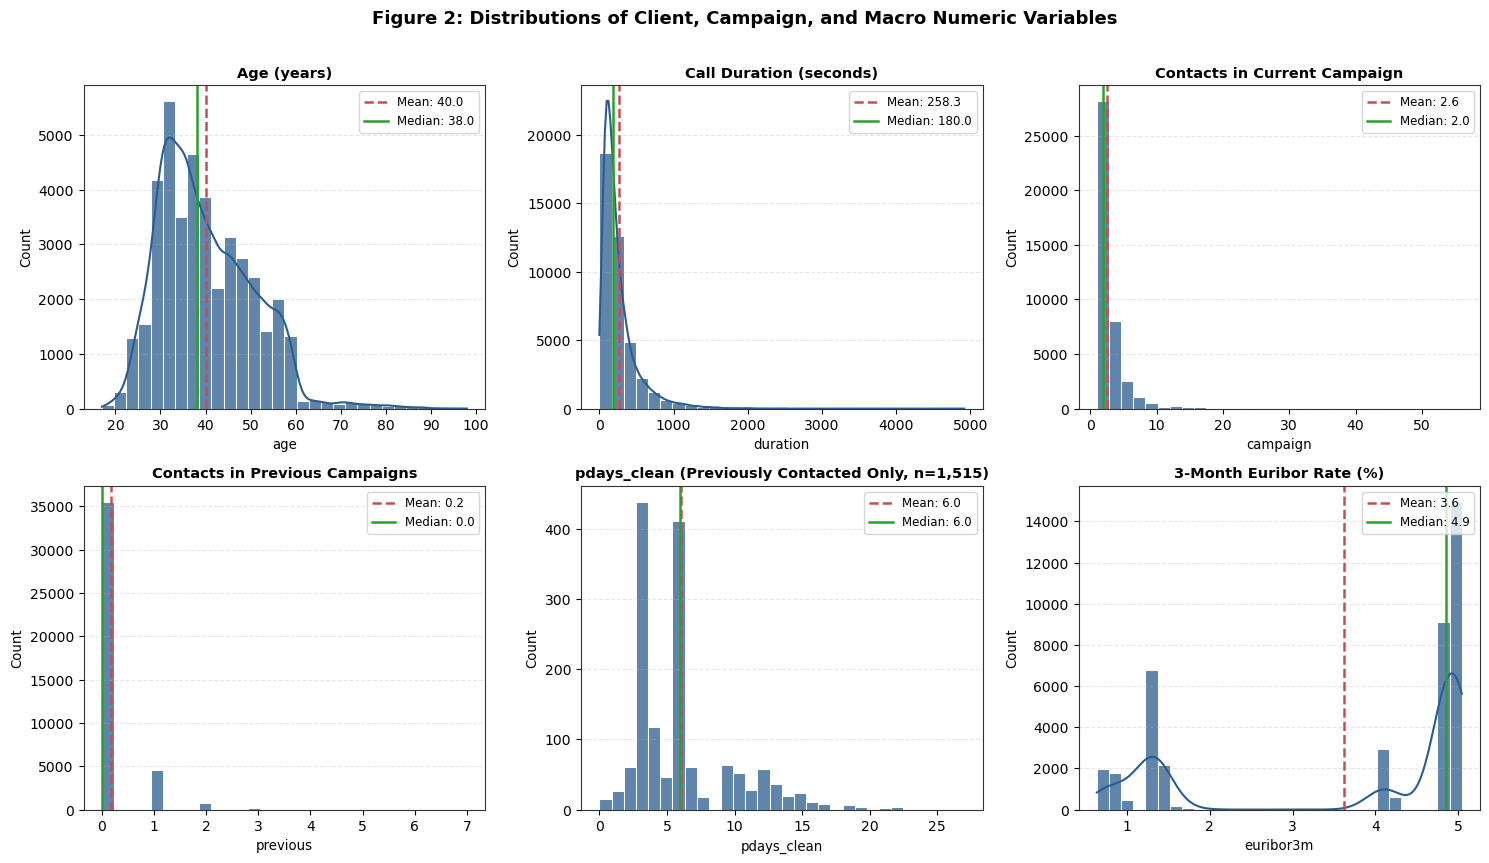

In [16]:
num_cols = ['age', 'duration', 'campaign', 'previous', 'previously_contacted', 'pdays_clean',
            'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed']

num_summary = df[num_cols].describe().T[['count', 'mean', 'std', 'min', '25%', '50%', '75%', 'max']]
num_summary['IQR'] = num_summary['75%'] - num_summary['25%']
print(num_summary.round(2).to_string())

fig, axes = plt.subplots(2, 3, figsize=(15, 8.5))
axes = axes.flatten()
plot_specs = [
    ('age', 'Age (years)', False),
    ('duration', 'Call Duration (seconds)', False),
    ('campaign', 'Contacts in Current Campaign', False),
    ('previous', 'Contacts in Previous Campaigns', False),
    ('pdays_clean', 'pdays_clean (Previously Contacted Only, n=1,515)', True),
    ('euribor3m', '3-Month Euribor Rate (%)', False)
]

for idx, (col, title, filter_pc) in enumerate(plot_specs):
    ax = axes[idx]
    data_ser = df.loc[df['previously_contacted'] == 1, col] if filter_pc else df[col]
    sns.histplot(data_ser, bins=30, kde=(col in ['age', 'duration', 'euribor3m']),
                 color=COLOR_MAIN, edgecolor='white', alpha=0.75, ax=ax)
    mean_v, med_v = data_ser.mean(), data_ser.median()
    ax.axvline(mean_v, color=COLOR_WARN, linestyle='--', linewidth=1.8, label=f'Mean: {mean_v:.1f}')
    ax.axvline(med_v, color='#2CA02C', linestyle='-', linewidth=1.8, label=f'Median: {med_v:.1f}')
    ax.set_title(title, fontsize=10.5, fontweight='bold')
    ax.set_xlabel(col, fontsize=9.5)
    ax.set_ylabel('Count', fontsize=9.5)
    ax.legend(fontsize=8.5, loc='upper right')
    ax.grid(axis='y', linestyle='--', alpha=0.3)

plt.suptitle('Figure 2: Distributions of Client, Campaign, and Macro Numeric Variables', fontsize=13, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig('fig2_numeric_distributions.png', dpi=200, bbox_inches='tight')
plt.show()


## 4. How Numeric Variables Differ by Target `y` 
(`fig3_numeric_by_target.png`)

            variable  y0_mean  y0_median  y0_IQR  y1_mean  y1_median  y1_IQR
                 age    39.91      38.00   15.00    40.91      37.00   19.00
            duration   220.87     164.00  184.00   553.26     449.00  488.00
            campaign     2.63       2.00    2.00     2.05       2.00    1.00
            previous     0.13       0.00    0.00     0.49       0.00    1.00
previously_contacted     0.01       0.00    0.00     0.21       0.00    0.00
         pdays_clean     0.09       0.00    0.00     1.23       0.00    0.00
        emp.var.rate     0.25       1.10    3.20    -1.23      -1.80    1.70
      cons.price.idx    93.60      93.92    0.92    93.35      93.20    1.03
       cons.conf.idx   -40.59     -41.80    6.30   -39.79     -40.40   10.10
           euribor3m     3.81       4.86    3.56     2.12       1.27    3.56
         nr.employed  5176.17    5195.80  129.00  5095.12    5099.10  173.50


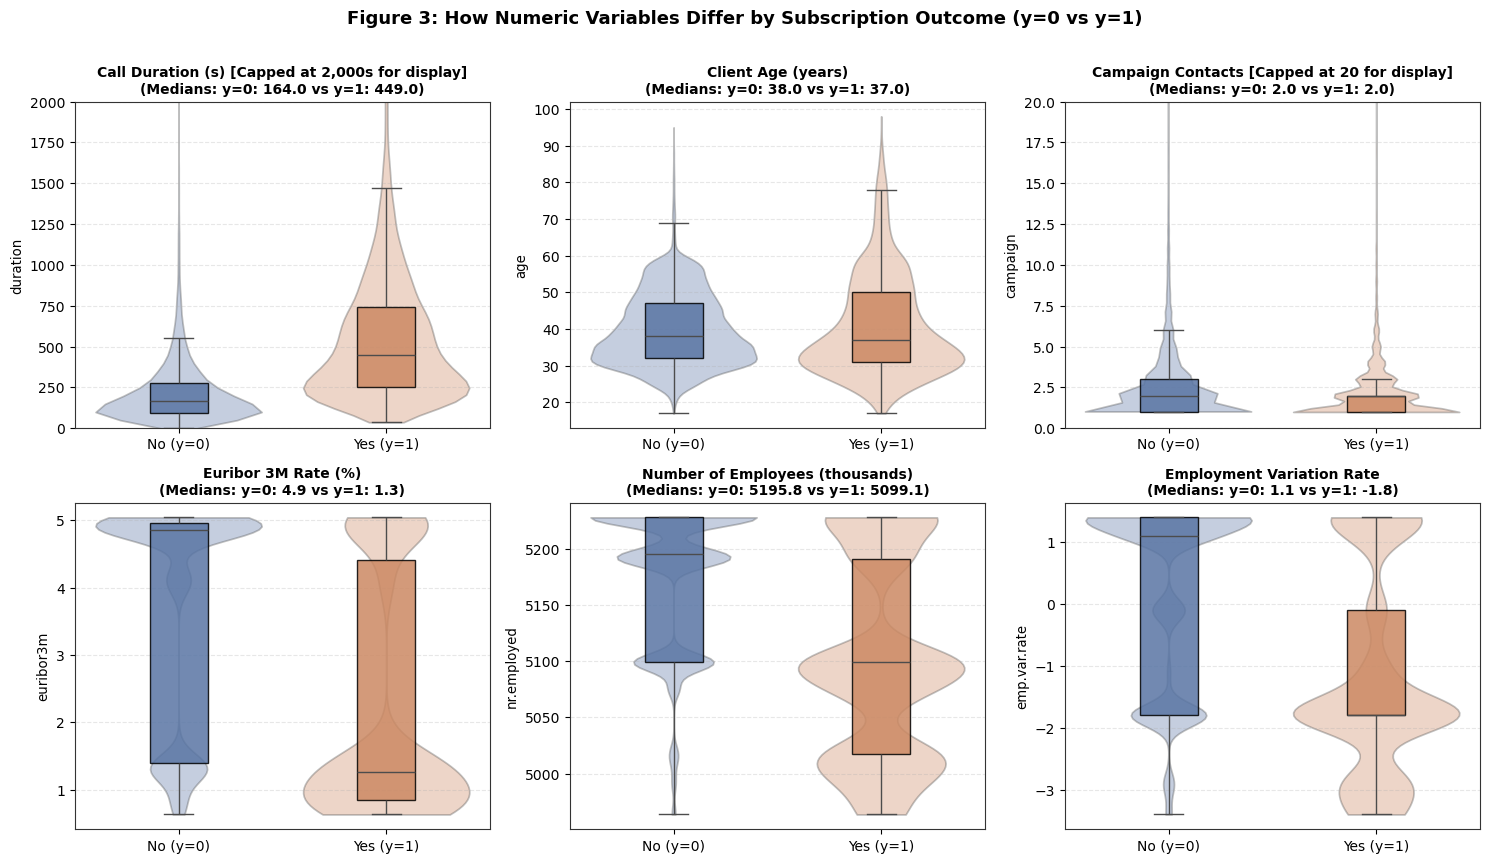

In [19]:

by_y_table = []
for col in num_cols:
    g0 = df.loc[df['y'] == 0, col]
    g1 = df.loc[df['y'] == 1, col]

    by_y_table.append({
        'variable': col,
        'y0_mean': round(g0.mean(), 2),
        'y0_median': round(g0.median(), 2),
        'y0_IQR': round(g0.quantile(0.75) - g0.quantile(0.25), 2),
        'y1_mean': round(g1.mean(), 2),
        'y1_median': round(g1.median(), 2),
        'y1_IQR': round(g1.quantile(0.75) - g1.quantile(0.25), 2)
    })

print(pd.DataFrame(by_y_table).to_string(index=False))

# Create a temporary DataFrame for plotting
plot_df = df.copy()
plot_df['y_label'] = plot_df['y'].map({
    0: 'No (y=0)',
    1: 'Yes (y=1)'
})

fig, axes = plt.subplots(2, 3, figsize=(15, 8.5))
axes = axes.flatten()

by_y_specs = [
    ('duration', 'Call Duration (s) [Capped at 2,000s for display]', (0, 2000)),
    ('age', 'Client Age (years)', None),
    ('campaign', 'Campaign Contacts [Capped at 20 for display]', (0, 20)),
    ('euribor3m', 'Euribor 3M Rate (%)', None),
    ('nr.employed', 'Number of Employees (thousands)', None),
    ('emp.var.rate', 'Employment Variation Rate', None)
]


for idx, (col, title, ylim) in enumerate(by_y_specs):
    ax = axes[idx]

    sns.violinplot(
        data=plot_df,
        x='y_label',
        y=col,
        hue='y_label',
        order=['No (y=0)', 'Yes (y=1)'],
        hue_order=['No (y=0)', 'Yes (y=1)'],
        palette=[COLOR_NO, COLOR_YES],
        inner=None,
        alpha=0.35,
        cut=0,
        dodge=False,
        legend=False,
        ax=ax
    )

    sns.boxplot(
        data=plot_df,
        x='y_label',
        y=col,
        hue='y_label',
        order=['No (y=0)', 'Yes (y=1)'],
        hue_order=['No (y=0)', 'Yes (y=1)'],
        palette=[COLOR_NO, COLOR_YES],
        width=0.28,
        showfliers=False,
        boxprops=dict(alpha=0.85, edgecolor='black'),
        dodge=False,
        legend=False,
        ax=ax
    )

    if ylim is not None:
        ax.set_ylim(ylim)

    med0 = df.loc[df['y'] == 0, col].median()
    med1 = df.loc[df['y'] == 1, col].median()

    ax.set_title(
        f"{title}\n(Medians: y=0: {med0:.1f} vs y=1: {med1:.1f})",
        fontsize=10,
        fontweight='bold'
    )

    ax.set_xlabel('')
    ax.set_ylabel(col, fontsize=9.5)
    ax.grid(axis='y', linestyle='--', alpha=0.3)

plt.suptitle(
    'Figure 3: How Numeric Variables Differ by Subscription Outcome (y=0 vs y=1)',
    fontsize=13,
    fontweight='bold',
    y=1.01
)

plt.tight_layout()
plt.savefig('fig3_numeric_by_target.png', dpi=200, bbox_inches='tight')
plt.show()


## 5. Correlations Between Numeric Variables
(`fig4_correlation_heatmap.png`)

y                       1.0000
duration                0.4053
previously_contacted    0.3249
pdays_clean             0.2671
previous                0.2302
cons.conf.idx           0.0548
age                     0.0304
campaign               -0.0664
cons.price.idx         -0.1361
emp.var.rate           -0.2983
euribor3m              -0.3077
nr.employed            -0.3547
Name: y, dtype: float64


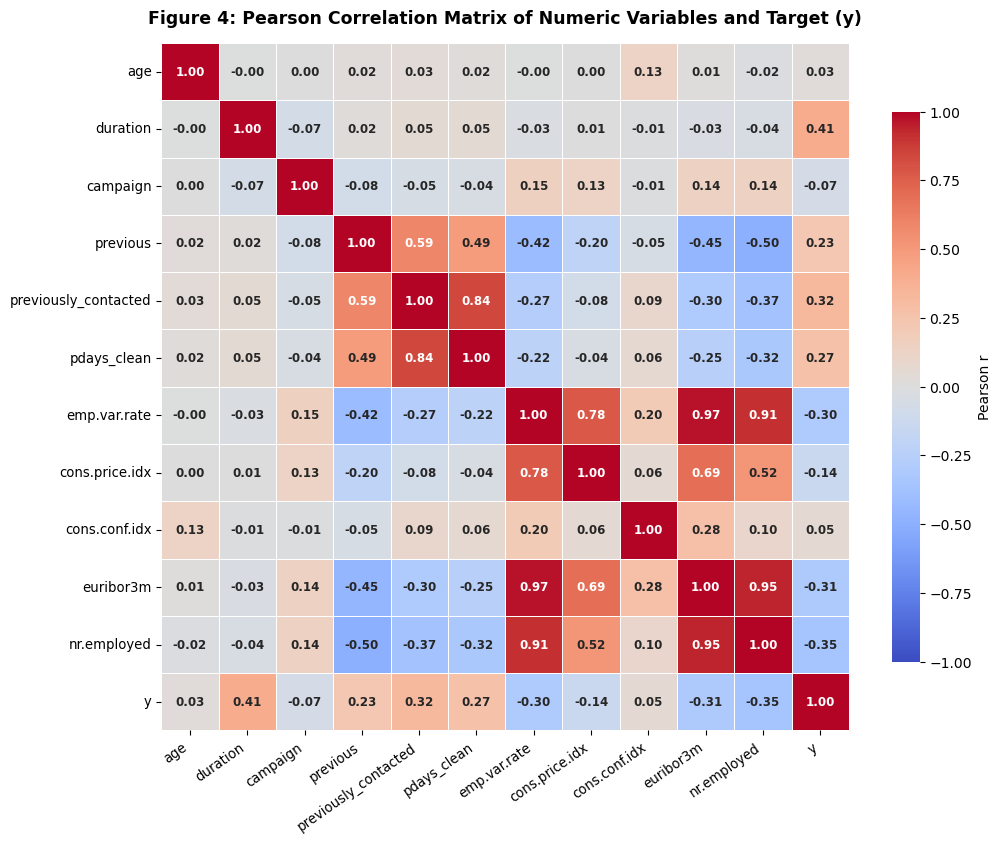

In [20]:
corr_cols = num_cols + ['y']
corr_mat = df[corr_cols].corr()
print(corr_mat['y'].sort_values(ascending=False).round(4))

fig, ax = plt.subplots(figsize=(10.5, 8.5))
sns.heatmap(corr_mat, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, center=0,
            square=True, linewidths=0.6, cbar_kws={'shrink': 0.8, 'label': 'Pearson r'}, ax=ax,
            annot_kws={'size': 8.5, 'fontweight': 'bold'})
ax.set_title('Figure 4: Pearson Correlation Matrix of Numeric Variables and Target (y)', fontsize=12.5, fontweight='bold', pad=14)
plt.xticks(rotation=35, ha='right', fontsize=9.5)
plt.yticks(rotation=0, fontsize=9.5)
plt.tight_layout()
plt.savefig('fig4_correlation_heatmap.png', dpi=200, bbox_inches='tight')
plt.show()


## 6. Subscription Rates by Categorical Variables
(`fig5`, `fig6`, `fig7`)

          job     n  yes      rate
      student   875  275 31.428571
      retired  1718  434 25.261932
   unemployed  1014  144 14.201183
       admin. 10419 1351 12.966695
   management  2924  328 11.217510
      unknown   330   37 11.212121
   technician  6739  730 10.832468
self-employed  1421  149 10.485574
    housemaid  1060  106 10.000000
 entrepreneur  1456  124  8.516484
     services  3967  323  8.142173
  blue-collar  9253  638  6.895061


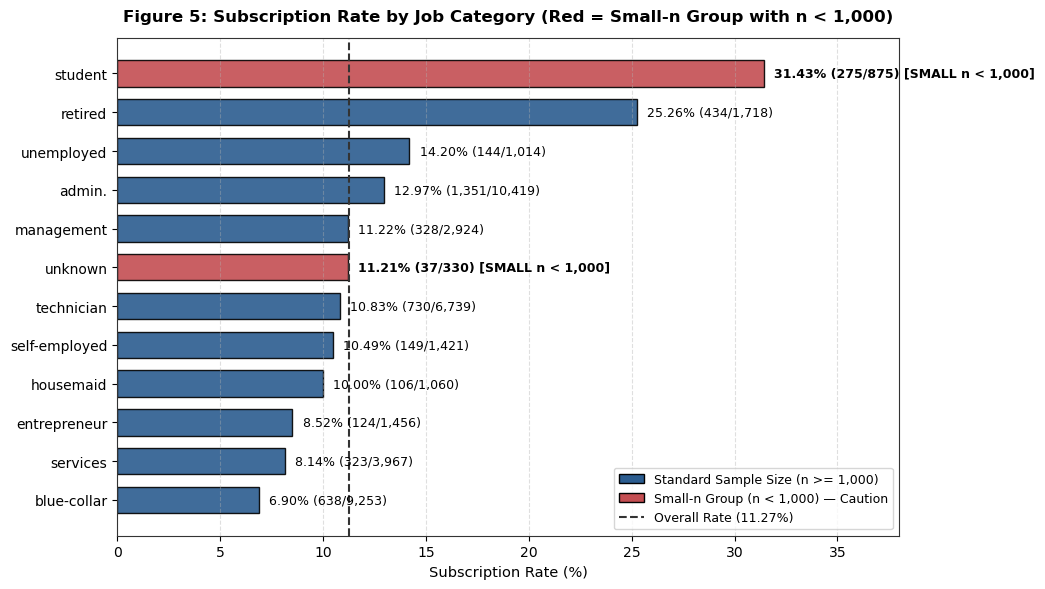

In [21]:
# Figure 5: Job Category Subscription Rates
job_stats = df.groupby('job')['y'].agg(n='count', yes='sum', rate=lambda s: s.mean()*100).reset_index()
job_stats = job_stats.sort_values(by='rate', ascending=True)
print(job_stats.sort_values(by='rate', ascending=False).to_string(index=False))

fig, ax = plt.subplots(figsize=(10.5, 6))
bar_colors = [COLOR_WARN if n < 1000 else COLOR_MAIN for n in job_stats['n']]
bars = ax.barh(job_stats['job'], job_stats['rate'], color=bar_colors, edgecolor='black', height=0.68, alpha=0.9)
ax.axvline(BASE_RATE, color='#333333', linestyle='--', linewidth=1.5, label=f'Overall Base Rate ({BASE_RATE:.2f}%)')
ax.set_xlim(0, 38)
ax.set_xlabel('Subscription Rate (%)', fontsize=10.5)
ax.set_title('Figure 5: Subscription Rate by Job Category (Red = Small-n Group with n < 1,000)', fontsize=12, fontweight='bold', pad=12)
ax.grid(axis='x', linestyle='--', alpha=0.4)

for bar, (_, row) in zip(bars, job_stats.iterrows()):
    flag_txt = ' [SMALL n < 1,000]' if row['n'] < 1000 else ''
    ax.text(row['rate'] + 0.5, bar.get_y() + bar.get_height()/2,
            f"{row['rate']:.2f}% ({int(row['yes']):,}/{int(row['n']):,}){flag_txt}",
            va='center', ha='left', fontsize=9, fontweight=('bold' if row['n'] < 1000 else 'normal'))

legend_elements = [
    Patch(facecolor=COLOR_MAIN, edgecolor='black', label='Standard Sample Size (n >= 1,000)'),
    Patch(facecolor=COLOR_WARN, edgecolor='black', label='Small-n Group (n < 1,000) — Caution'),
    Line2D([0], [0], color='#333333', lw=1.5, ls='--', label=f'Overall Rate ({BASE_RATE:.2f}%)')
]
ax.legend(handles=legend_elements, loc='lower right', fontsize=9)
plt.tight_layout()
plt.savefig('fig5_job_subscription_rates.png', dpi=200, bbox_inches='tight')
plt.show()


month     n  yes      rate
  mar   546  276 50.549451
  apr  2631  539 20.486507
  may 13767  886  6.435680
  jun  5318  559 10.511470
  jul  7169  648  9.038918
  aug  6176  655 10.605570
  sep   570  256 44.912281
  oct   717  315 43.933054
  nov  4100  416 10.146341
  dec   182   89 48.901099


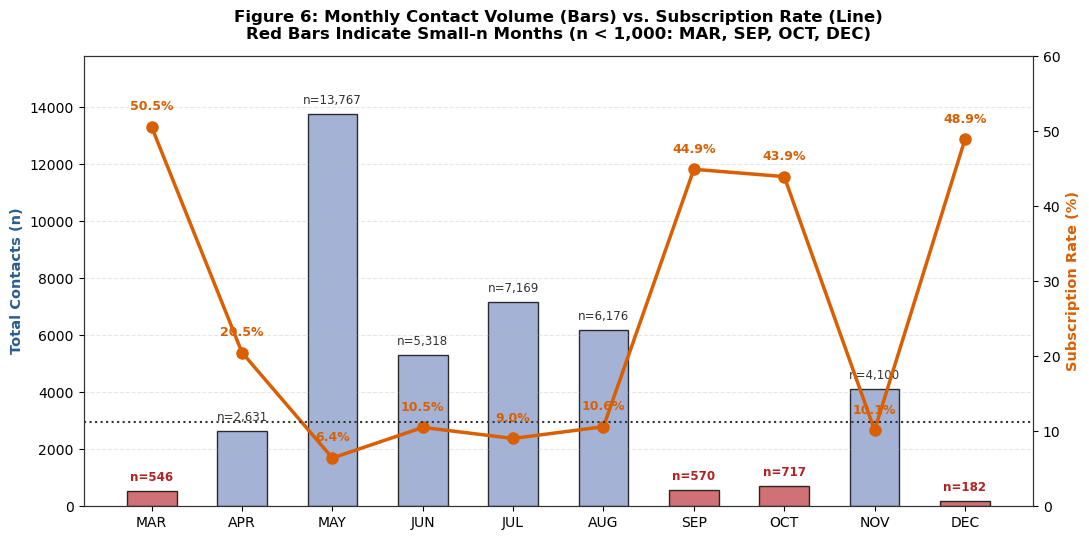

In [22]:
# Figure 6: Monthly Contact Volume & Subscription Rate
month_order = ['mar', 'apr', 'may', 'jun', 'jul', 'aug', 'sep', 'oct', 'nov', 'dec']
m_stats = df.groupby('month')['y'].agg(n='count', yes='sum', rate=lambda s: s.mean()*100).reindex(month_order).reset_index()
print(m_stats.to_string(index=False))

fig, ax1 = plt.subplots(figsize=(11, 5.5))
ax2 = ax1.twinx()

bar_cols_m = [COLOR_WARN if n < 1000 else '#8DA0CB' for n in m_stats['n']]
ax1.bar(m_stats['month'].str.upper(), m_stats['n'], color=bar_cols_m, edgecolor='black', width=0.55, alpha=0.8)
ax2.plot(m_stats['month'].str.upper(), m_stats['rate'], color='#D95F02', marker='o', linewidth=2.5, markersize=8)
ax2.axhline(BASE_RATE, color='#333333', linestyle=':', linewidth=1.5)

ax1.set_ylabel('Total Contacts (n)', fontsize=10.5, color='#2B5C8F', fontweight='bold')
ax2.set_ylabel('Subscription Rate (%)', fontsize=10.5, color='#D95F02', fontweight='bold')
ax1.set_ylim(0, 15800)
ax2.set_ylim(0, 60)
ax1.grid(axis='y', linestyle='--', alpha=0.3)

for idx, row in m_stats.iterrows():
    ax1.text(idx, row['n'] + 250, f"n={int(row['n']):,}", ha='center', va='bottom', fontsize=8.5,
             color=('#B22222' if row['n'] < 1000 else '#333333'), fontweight=('bold' if row['n'] < 1000 else 'normal'))
    ax2.text(idx, row['rate'] + 1.8, f"{row['rate']:.1f}%", ha='center', va='bottom', fontsize=9, fontweight='bold', color='#D95F02')

ax1.set_title('Figure 6: Monthly Contact Volume (Bars) vs. Subscription Rate (Line)\nRed Bars Indicate Small-n Months (n < 1,000: MAR, SEP, OCT, DEC)', fontsize=12, fontweight='bold', pad=12)
plt.tight_layout()
plt.savefig('fig6_month_volume_and_rate.png', dpi=200, bbox_inches='tight')
plt.show()



--- poutcome ---
   poutcome     n  yes      rate
    success  1373  894 65.112891
    failure  4252  605 14.228598
nonexistent 35551 3140  8.832382

--- contact ---
  contact     n  yes      rate
 cellular 26135 3852 14.738856
telephone 15041  787  5.232365

--- previously_contacted ---
 previously_contacted     n  yes      rate
                    1  1515  967 63.828383
                    0 39661 3672  9.258465


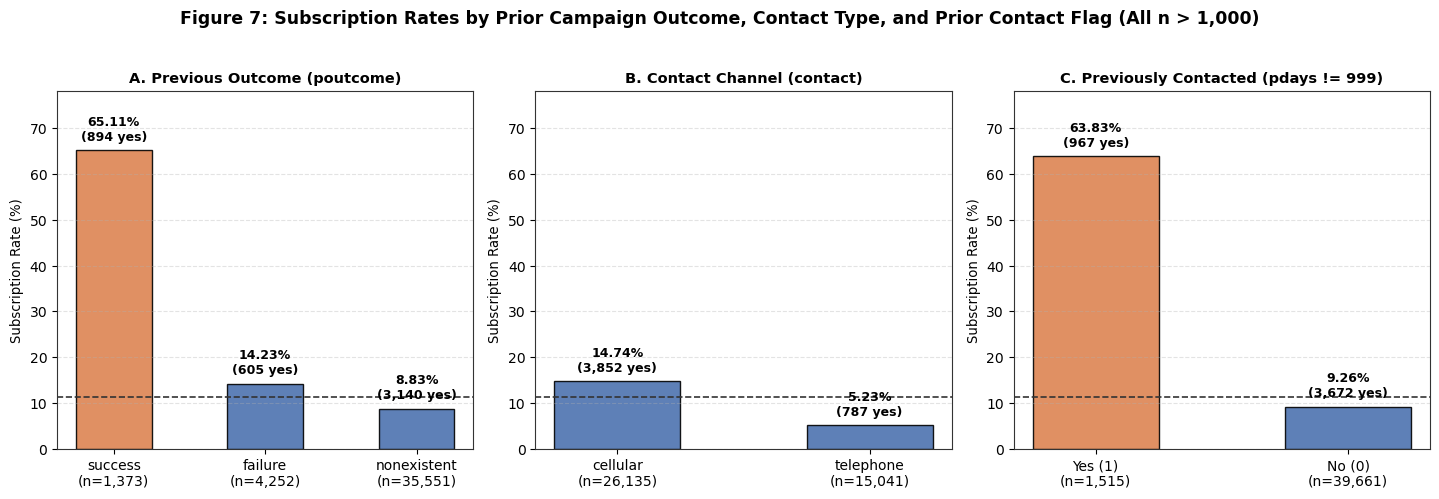

In [23]:
# Figure 7: poutcome, contact, and previously_contacted
fig, axes = plt.subplots(1, 3, figsize=(14.5, 4.8))
cat_panels = [
    ('poutcome', 'A. Previous Outcome (poutcome)', ['success', 'failure', 'nonexistent']),
    ('contact', 'B. Contact Channel (contact)', ['cellular', 'telephone']),
    ('previously_contacted', 'C. Previously Contacted (pdays != 999)', [1, 0])
]

for ax, (col, title, order) in zip(axes, cat_panels):
    st = df.groupby(col)['y'].agg(n='count', yes='sum', rate=lambda s: s.mean()*100).reindex(order).reset_index()
    print(f"\n--- {col} ---")
    print(st.to_string(index=False))
    x_labels = [f"{str(val)}\n(n={int(n):,})" for val, n in zip(st[col], st['n'])]
    if col == 'previously_contacted':
        x_labels = [f"{'Yes (1)' if val==1 else 'No (0)'}\n(n={int(n):,})" for val, n in zip(st[col], st['n'])]
    bars = ax.bar(x_labels, st['rate'], color=[COLOR_YES if r > 20 else COLOR_NO for r in st['rate']],
                  edgecolor='black', width=0.5, alpha=0.9)
    ax.axhline(BASE_RATE, color='#333333', linestyle='--', linewidth=1.2)
    ax.set_ylim(0, 78)
    ax.set_title(title, fontsize=10.5, fontweight='bold')
    ax.set_ylabel('Subscription Rate (%)', fontsize=9.5)
    ax.grid(axis='y', linestyle='--', alpha=0.35)
    for bar, (_, row) in zip(bars, st.iterrows()):
        ax.text(bar.get_x() + bar.get_width()/2, row['rate'] + 1.5,
                f"{row['rate']:.2f}%\n({int(row['yes']):,} yes)", ha='center', va='bottom', fontsize=9, fontweight='bold')

plt.suptitle('Figure 7: Subscription Rates by Prior Campaign Outcome, Contact Type, and Prior Contact Flag (All n > 1,000)', fontsize=12.5, fontweight='bold', y=1.03)
plt.tight_layout()
plt.savefig('fig7_poutcome_contact_rates.png', dpi=200, bbox_inches='tight')
plt.show()


## 7. Macro / Social-Economic Indicators 
(`fig8_macro_regimes_analysis.png`)


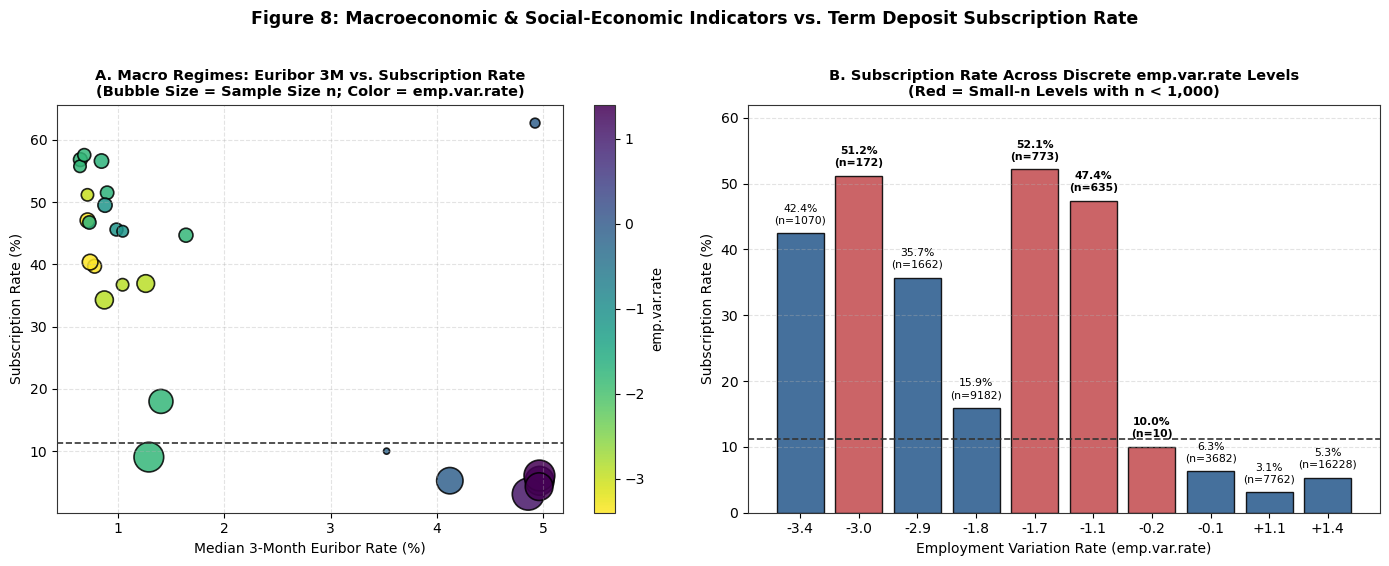

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

reg = df.groupby(['emp.var.rate', 'nr.employed', 'cons.price.idx']).agg(
    n=('y', 'count'), yes=('y', 'sum'), rate=('y', lambda s: s.mean()*100), euribor=('euribor3m', 'median')
).reset_index()

scatter = axes[0].scatter(reg['euribor'], reg['rate'], s=np.sqrt(reg['n'])*6, c=reg['emp.var.rate'],
                          cmap='viridis_r', alpha=0.85, edgecolors='black', linewidth=1.2)
cbar = plt.colorbar(scatter, ax=axes[0])
cbar.set_label('emp.var.rate', fontsize=9.5)
axes[0].axhline(BASE_RATE, color='#333333', linestyle='--', linewidth=1.2)
axes[0].set_title('A. Macro Regimes: Euribor 3M vs. Subscription Rate\n(Bubble Size = Sample Size n; Color = emp.var.rate)', fontsize=10.5, fontweight='bold')
axes[0].set_xlabel('Median 3-Month Euribor Rate (%)', fontsize=10)
axes[0].set_ylabel('Subscription Rate (%)', fontsize=10)
axes[0].grid(True, linestyle='--', alpha=0.35)

emp_st = df.groupby('emp.var.rate')['y'].agg(n='count', yes='sum', rate=lambda s: s.mean()*100).reset_index()
emp_st['label'] = [f"{r['emp.var.rate']:+.1f}" for _, r in emp_st.iterrows()]
bar_c = [COLOR_WARN if n < 1000 else COLOR_MAIN for n in emp_st['n']]
bars2 = axes[1].bar(emp_st['label'], emp_st['rate'], color=bar_c, edgecolor='black', alpha=0.88)
axes[1].axhline(BASE_RATE, color='#333333', linestyle='--', linewidth=1.2)
axes[1].set_ylim(0, 62)
axes[1].set_title('B. Subscription Rate Across Discrete emp.var.rate Levels\n(Red = Small-n Levels with n < 1,000)', fontsize=10.5, fontweight='bold')
axes[1].set_xlabel('Employment Variation Rate (emp.var.rate)', fontsize=10)
axes[1].set_ylabel('Subscription Rate (%)', fontsize=10)
axes[1].grid(axis='y', linestyle='--', alpha=0.35)
for bar, (_, r) in zip(bars2, emp_st.iterrows()):
    axes[1].text(bar.get_x() + bar.get_width()/2, r['rate'] + 1.2,
                 f"{r['rate']:.1f}%\n(n={int(r['n'])})", ha='center', va='bottom', fontsize=7.8,
                 fontweight=('bold' if r['n']<1000 else 'normal'))

plt.suptitle('Figure 8: Macroeconomic & Social-Economic Indicators vs. Term Deposit Subscription Rate', fontsize=12.5, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('fig8_macro_regimes_analysis.png', dpi=200, bbox_inches='tight')
plt.show()


## 8. Categorical `"unknown"` Audit & Target Rates
(`fig9_unknown_categories_audit.png`)


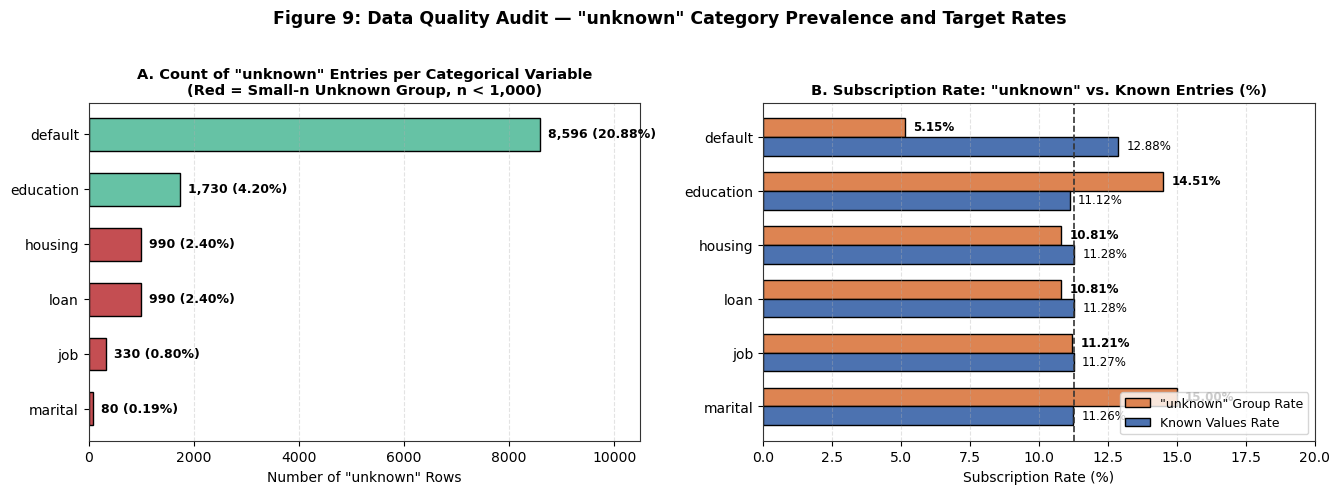

In [25]:
unk_rows = []
for col in ['default', 'education', 'housing', 'loan', 'job', 'marital']:
    sub_u = df[df[col] == 'unknown']
    sub_k = df[df[col] != 'unknown']
    unk_rows.append({
        'variable': col, 'unk_n': len(sub_u), 'unk_pct': len(sub_u) / len(df) * 100,
        'unk_yes': int(sub_u['y'].sum()), 'unk_rate': sub_u['y'].mean() * 100, 'known_rate': sub_k['y'].mean() * 100
    })
unk_df = pd.DataFrame(unk_rows).sort_values(by='unk_n', ascending=True)

fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.8))
b1 = axes[0].barh(unk_df['variable'], unk_df['unk_n'],
                  color=[COLOR_WARN if n < 1000 else '#66C2A5' for n in unk_df['unk_n']],
                  edgecolor='black', height=0.6)
axes[0].set_xlim(0, 10500)
axes[0].set_title('A. Count of "unknown" Entries per Categorical Variable\n(Red = Small-n Unknown Group, n < 1,000)', fontsize=10.5, fontweight='bold')
axes[0].set_xlabel('Number of "unknown" Rows', fontsize=10)
axes[0].grid(axis='x', linestyle='--', alpha=0.35)
for bar, (_, r) in zip(b1, unk_df.iterrows()):
    axes[0].text(r['unk_n'] + 150, bar.get_y() + bar.get_height()/2,
                 f"{int(r['unk_n']):,} ({r['unk_pct']:.2f}%)", va='center', fontsize=9, fontweight='bold')

y_pos = np.arange(len(unk_df))
h = 0.35
axes[1].barh(y_pos + h/2, unk_df['unk_rate'], height=h, color=COLOR_YES, edgecolor='black', label='"unknown" Group Rate')
axes[1].barh(y_pos - h/2, unk_df['known_rate'], height=h, color=COLOR_NO, edgecolor='black', label='Known Values Rate')
axes[1].axvline(BASE_RATE, color='#333333', linestyle='--', linewidth=1.2)
axes[1].set_yticks(y_pos)
axes[1].set_yticklabels(unk_df['variable'])
axes[1].set_xlim(0, 20)
axes[1].set_title('B. Subscription Rate: "unknown" vs. Known Entries (%)', fontsize=10.5, fontweight='bold')
axes[1].set_xlabel('Subscription Rate (%)', fontsize=10)
axes[1].legend(loc='lower right', fontsize=9)
axes[1].grid(axis='x', linestyle='--', alpha=0.35)
for idx, (_, r) in enumerate(unk_df.iterrows()):
    axes[1].text(r['unk_rate'] + 0.3, idx + h/2, f"{r['unk_rate']:.2f}%", va='center', fontsize=8.5, fontweight='bold')
    axes[1].text(r['known_rate'] + 0.3, idx - h/2, f"{r['known_rate']:.2f}%", va='center', fontsize=8.5)

plt.suptitle('Figure 9: Data Quality Audit — "unknown" Category Prevalence and Target Rates', fontsize=12.5, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('fig9_unknown_categories_audit.png', dpi=200, bbox_inches='tight')
plt.show()


# Data Processing - continue

## Step 3: Setup for model training

In [26]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import StandardScaler

RANDOM_STATE = 42          # one seed for every random step: split, CV folds, models
np.random.seed(RANDOM_STATE)
pd.set_option("display.max_columns", 60)

## Encode categorical features (one-hot)

In [27]:
TARGET = "y"
CATEGORICAL_COLS = ["job", "marital", "education", "default", "housing", "loan",
                    "contact", "month", "day_of_week", "poutcome"]
NUMERIC_COLS = ["age", "duration", "campaign", "pdays_clean", "previous",
                "emp.var.rate", "cons.price.idx", "cons.conf.idx", "euribor3m", "nr.employed"]
BINARY_COLS = ["previously_contacted"]          # already 0/1, no encoding or scaling needed

# every cleaned column must belong to exactly one group
assert set(CATEGORICAL_COLS + NUMERIC_COLS + BINARY_COLS + [TARGET]) == set(df.columns)

df_model = pd.get_dummies(df, columns=CATEGORICAL_COLS, drop_first=True, dtype=int)
print("Shape after one-hot encoding:", df_model.shape)
df_model.head()

Shape after one-hot encoding: (41176, 55)


,age,duration,campaign,previous,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y,previously_contacted,pdays_clean,job_blue-collar,job_entrepreneur,job_housemaid,job_management,job_retired,job_self-employed,job_services,job_student,job_technician,job_unemployed,job_unknown,marital_married,marital_single,marital_unknown,education_basic.6y,education_basic.9y,education_high.school,education_illiterate,education_professional.course,education_university.degree,education_unknown,default_unknown,default_yes,housing_unknown,housing_yes,loan_unknown,loan_yes,contact_telephone,month_aug,month_dec,month_jul,month_jun,month_mar,month_may,month_nov,month_oct,month_sep,day_of_week_mon,day_of_week_thu,day_of_week_tue,day_of_week_wed,poutcome_nonexistent,poutcome_success
0,56,261,1,0,1.1,93.994,-36.4,4.857,5191.0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,1,0,0,0,1,0,0,0,1,0
1,57,149,1,0,1.1,93.994,-36.4,4.857,5191.0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0,0,1,0,0,0,0,1,0,0,0,0,0,1,0,0,0,0,0,1,0,0,0,1,0,0,0,1,0
2,37,226,1,0,1.1,93.994,-36.4,4.857,5191.0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0,0,1,0,0,0,0,0,0,0,1,0,0,1,0,0,0,0,0,1,0,0,0,1,0,0,0,1,0
3,40,151,1,0,1.1,93.994,-36.4,4.857,5191.0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,1,0,0,0,1,0,0,0,1,0
4,56,307,1,0,1.1,93.994,-36.4,4.857,5191.0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,1,0,0,0,1,0,0,0,1,0


## Train / test split

In [28]:
X = df_model.drop(columns=[TARGET])
y = df_model[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

print("Train:", X_train.shape, "  Test:", X_test.shape)
print(f"Subscription rate  train: {y_train.mean():.4f}   test: {y_test.mean():.4f}")

Train: (32940, 54)   Test: (8236, 54)
Subscription rate  train: 0.1127   test: 0.1127


## Feature sets with / without duration

In [29]:
featurewithduration = list(X_train.columns)
featurenoduration = [c for c in featurewithduration if c != "duration"]

print(len(featurewithduration), "features with duration |", len(featurenoduration), "features without duration")


54 features with duration | 53 features without duration


## Feature scaling

In [31]:
scaler = StandardScaler()
X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()
X_train_scaled[NUMERIC_COLS] = scaler.fit_transform(X_train[NUMERIC_COLS])   # fit on TRAIN only
X_test_scaled[NUMERIC_COLS] = scaler.transform(X_test[NUMERIC_COLS])         # reuse the training mean / std

X_train_scaled[NUMERIC_COLS].describe().loc[["mean", "std"]].round(3)

,age,duration,campaign,pdays_clean,previous,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed
mean,-0.0,0.0,-0.0,0.0,0.0,-0.0,0.0,0.0,-0.0,-0.0
std,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


## 5-fold cross-validation

In [32]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
SCORING = ["accuracy", "precision", "recall", "f1", "roc_auc"]
REFIT_METRIC = "f1"

# Model Training

As training models is happend during semester, in case each time open Jupyternotebook we have to spend time re-training the models, here we setup some functions to save model.

In [34]:
from pathlib import Path
import os
import joblib
import sklearn

# Create the root directory for model caches
MODEL_DIR = Path("model_cache").resolve()
MODEL_DIR.mkdir(parents=True, exist_ok=True)

# Preserve existing in-memory models; create an empty dictionary if absent
grids = globals().get("grids", {})


# Register input types and feature lists for all models
# SVM performs scaling inside its Pipeline, so it uses raw inputs
MODEL_INPUTS = {
    "LR (no duration)": ("scaled", featurenoduration),
    "LR (with duration)": ("scaled", featurewithduration),

    "DT (no duration)": ("raw", featurenoduration),
    "DT (with duration)": ("raw", featurewithduration),

    "SVM (no duration)": ("raw", featurenoduration),
    "SVM (with duration)": ("raw", featurewithduration),

    "RF (no duration)": ("raw", featurenoduration),
    "RF (with duration)": ("raw", featurewithduration),

    "GB (no duration)": ("raw", featurenoduration),
    "GB (with duration)": ("raw", featurewithduration),
}

# Generate an experiment identifier from data, preprocessing, and version
CONTEXT_ID = joblib.hash({
    "X_train": X_train,
    "X_test": X_test,
    "y_train": y_train,
    "y_test": y_test,
    "scaler": scaler,
    "numeric_cols": NUMERIC_COLS,
    "model_inputs": MODEL_INPUTS,
    "sklearn_version": sklearn.__version__,
})

# Create the output directory for this experiment
RUN_DIR = MODEL_DIR / CONTEXT_ID
RUN_DIR.mkdir(parents=True, exist_ok=True)



In [35]:

def atomic_dump(obj, path):
   # Write a temporary file before replacing the target.
    path = Path(path)
    temp = path.with_suffix(path.suffix + ".tmp")

    joblib.dump(obj, temp, compress=3)
    os.replace(temp, path)

# Save evaluation context, including input specifications for all models
atomic_dump({
    "sklearn_version": sklearn.__version__,
    "scaler": scaler,
    "numeric_cols": NUMERIC_COLS,
    "model_inputs": MODEL_INPUTS,
    "X_test": X_test,
    "X_test_scaled": X_test_scaled,
    "y_test": y_test,
}, RUN_DIR / "evaluation_context.joblib")


def cache_path(
    name,
    estimator,
    param_grid,
    X_tr,
    scoring=SCORING,
    refit=REFIT_METRIC,
    cv_spec=cv,
):


    # Generate a cache identifier from the model, training data, and search settings
    signature = joblib.hash({
        "name": name,
        "estimator": estimator,
        "param_grid": param_grid,
        "X_train": X_tr,
        "y_train": y_train,
        "scoring": scoring,
        "refit": refit,
        "cv": cv_spec,
    })

    return RUN_DIR / f"search_{signature}.joblib"


def save_grid(name, grid, X_tr):
    # Save a fitted GridSearchCV object.
    # Determine the save path using the actual search configuration
    path = cache_path(
        name,
        grid.estimator,
        grid.param_grid,
        X_tr,
        scoring=grid.scoring,
        refit=grid.refit,
        cv_spec=grid.cv,
    )

    # Save the best model, best parameters, and complete CV results
    atomic_dump({
        "name": name,
        "grid": grid,
    }, path)

    return path


print("Cache setup completed.")
print("Registered models:", len(MODEL_INPUTS))
print("Results directory:", RUN_DIR)

Cache setup completed.
Registered models: 10
Results directory: D:\Software\JupyterNotebooks\NTU\KM6312_GroupProject\bank-additional\Final\model_cache\02fd97b872b9d2d4b7384550c3b87592


In [37]:
def fit_model(name, estimator, param_grid, X_tr, *,
              force_retrain=False, n_jobs=2):
    path = cache_path(name, estimator, param_grid, X_tr)

    if path.exists() and not force_retrain:
        grid = joblib.load(path)["grid"]
        print(f"[Loaded] {name}")
    else:
        grid = GridSearchCV(
            estimator,
            param_grid,
            cv=cv,
            scoring=SCORING,
            refit=REFIT_METRIC,
            n_jobs=n_jobs,
            verbose=2,        
            pre_dispatch=n_jobs,
            error_score="raise",
        )
        grid.fit(X_tr, y_train)

        save_grid(name, grid, X_tr)
        print(f"[Trained & saved] {name}")

    grids[name] = grid

    i = grid.best_index_
    metric = grid.refit
    print("Best parameters:", grid.best_params_)
    print(
        f"CV {metric}: "
        f"{grid.cv_results_[f'mean_test_{metric}'][i]:.4f} ± "
        f"{grid.cv_results_[f'std_test_{metric}'][i]:.4f}"
    )

    return grid.best_estimator_

## Logistic Regression & Decision Tree

In [39]:
#reuse function
def plot_lr_coefficients(name, k=10):
    #The k largest coefficients of a fitted LR model (continuous features are standardised, so they are comparable).
    model = grids[name].best_estimator_
    coefs = pd.Series(model.coef_[0], index=model.feature_names_in_)
    top = coefs.reindex(coefs.abs().nlargest(k).index)[::-1]
    fig, ax = plt.subplots(figsize=(7.5, 4.6))
    ax.barh(top.index, top.values, color=["#2a78d6" if v > 0 else "#e34948" for v in top.values])
    ax.axvline(0, linewidth=0.8)
    ax.set_title(f"{name}: {k} largest coefficients\nblue = raises the odds of 'yes', red = lowers them",
                 fontsize=11, loc="left")
    ax.grid(axis="x")
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    plt.tight_layout()
    plt.show()

In [40]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.model_selection import GridSearchCV
from sklearn import metrics

lr_grid = {"C": [0.001, 0.01, 0.1, 1, 10, 100]}


### Model 1: Logistic Regression without duration

Fitting 5 folds for each of 6 candidates, totalling 30 fits
[Trained & saved] LR (no duration)
Best parameters: {'C': 10}
CV f1: 0.3457 ± 0.0063


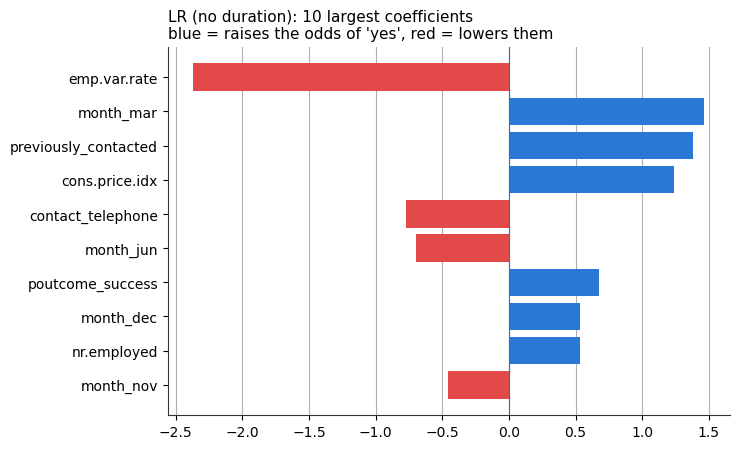

In [41]:
lr_no_duration = fit_model("LR (no duration)",
                           LogisticRegression(solver="lbfgs", max_iter=1000),
                           lr_grid,
                           X_train_scaled[featurenoduration])
plot_lr_coefficients("LR (no duration)")

In [42]:
X_train[["emp.var.rate", "cons.price.idx", "euribor3m", "nr.employed"]].corr().round(2)

,emp.var.rate,cons.price.idx,euribor3m,nr.employed
emp.var.rate,1.00,0.77,0.97,0.91
cons.price.idx,0.77,1.00,0.69,0.52
euribor3m,0.97,0.69,1.00,0.94
nr.employed,0.91,0.52,0.94,1.00


In [43]:
# Impurity of the root node (= the whole training set), computed with the two formulas above
p = y_train.value_counts(normalize=True).sort_index().values          # [p_no, p_yes]
gini_root = 1 - np.sum(p ** 2)
entropy_root = -np.sum(p * np.log2(p))
print(f"Class proportions in the training set: no = {p[0]:.4f}, yes = {p[1]:.4f}")
print(f"Root Gini impurity  G = 1 - sum(p_i^2)        = {gini_root:.4f}   (maximum 0.5 for two classes)")
print(f"Root entropy        H = -sum(p_i * log2(p_i)) = {entropy_root:.4f}   (maximum 1 for two classes)")

Class proportions in the training set: no = 0.8873, yes = 0.1127
Root Gini impurity  G = 1 - sum(p_i^2)        = 0.1999   (maximum 0.5 for two classes)
Root entropy        H = -sum(p_i * log2(p_i)) = 0.5079   (maximum 1 for two classes)


### DT model settings

In [44]:
# (a) cost-complexity pruning path: alpha = 0 is the unpruned (full) tree
CCP_ALPHAS = [0.0, 1e-5, 3e-5, 1e-4, 2e-4, 3e-4, 5e-4, 1e-3, 2e-3, 5e-3]

# (b) joint grid over the key parameters (2 x 5 x 3 x 3 x 4 = 360 settings x 5 folds; ~2-3 min per model)
DT_GRID = {"criterion": ["gini", "entropy"],
           "max_depth": [5, 7, 10, 15, None],
           "min_samples_split": [2, 50, 200],
           "min_samples_leaf": [1, 20, 50],
           "ccp_alpha": [0.0, 1e-4, 3e-4, 1e-3]}


def pruning_curve(cols, title):
    """Unpruned tree (alpha = 0) and cost-complexity pruning over CCP_ALPHAS, each scored with the shared 5-fold CV."""
    grid = GridSearchCV(DecisionTreeClassifier(random_state=RANDOM_STATE), {"ccp_alpha": CCP_ALPHAS},
                        cv=cv, scoring=["accuracy", "f1"], refit=False, return_train_score=True, n_jobs=-1)
    grid.fit(X_train[cols], y_train)
    res = grid.cv_results_
    trees = [DecisionTreeClassifier(random_state=RANDOM_STATE, ccp_alpha=a).fit(X_train[cols], y_train)
             for a in CCP_ALPHAS]
    table = pd.DataFrame({"ccp_alpha": CCP_ALPHAS,
                          "terminal nodes |T|": [t.get_n_leaves() for t in trees],
                          "depth": [t.get_depth() for t in trees],
                          "train F1": res["mean_train_f1"], "CV F1": res["mean_test_f1"],
                          "train accuracy": res["mean_train_accuracy"], "CV accuracy": res["mean_test_accuracy"]})
    display(table.round({c: 4 for c in table.columns if c != "ccp_alpha"}))   # keep small alphas visible

    xpos = np.arange(len(CCP_ALPHAS))
    xlabels = ["0\n(unpruned)"] + [f"{a:g}" for a in CCP_ALPHAS[1:]]
    best = int(table["CV F1"].idxmax())
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.2))
    ax1.plot(xpos, table["train F1"], linestyle="--", linewidth=2, marker="o", markersize=6, label="training folds")
    ax1.plot(xpos, table["CV F1"], linewidth=2, marker="o", markersize=6, label="validation folds (CV)")
    ax1.annotate(f"best CV F1 = {table['CV F1'][best]:.3f}\nα = {CCP_ALPHAS[best]:g}, |T| = {table['terminal nodes |T|'][best]}",
                 (xpos[best], table["CV F1"][best]), xytext=(0, -38), textcoords="offset points",
                 ha="center", fontsize=8)
    ax1.set_ylim(0, 1.05)
    ax1.set_ylabel("F1 (mean of 5 folds)")
    ax1.set_title(f"{title}: F1 vs pruning strength α", fontsize=11, loc="left")
    ax1.legend(frameon=False, fontsize=9, loc="upper right")

    bars = ax2.bar(xpos, table["terminal nodes |T|"])
    ax2.bar_label(bars, padding=2, fontsize=8)
    ax2.set_yscale("log")
    ax2.set_ylabel("terminal nodes |T| (log scale)")
    ax2.set_title(f"{title}: tree size vs α", fontsize=11, loc="left")
    for ax in (ax1, ax2):
        ax.set_xticks(xpos, xlabels, fontsize=8)
        ax.set_xlabel("ccp_alpha (α)")
        ax.grid(axis="y")
        ax.set_axisbelow(True)
        for side in ("top", "right"):
            ax.spines[side].set_visible(False)
    plt.tight_layout()
    plt.show()
    return table


def describe_selected_tree(name, k=5):
    """Size of the selected tree and the k best settings of the grid search (mean ± std of CV F1)."""
    grid = grids[name]
    tree = grid.best_estimator_
    print(f"Selected tree: criterion = {tree.criterion}, depth = {tree.get_depth()}, "
          f"terminal nodes |T| = {tree.get_n_leaves()}")
    top = pd.DataFrame(grid.cv_results_).sort_values(f"rank_test_{REFIT_METRIC}").head(k)
    print(f"\nTop {k} of {len(grid.cv_results_['params'])} settings by mean CV {REFIT_METRIC}:")
    settings = pd.DataFrame([{key: str(v) for key, v in p.items()} for p in top["params"]])   # keeps max_depth=None readable
    settings[f"mean CV {REFIT_METRIC}"] = top[f"mean_test_{REFIT_METRIC}"].values.round(4)
    settings["std"] = top[f"std_test_{REFIT_METRIC}"].values.round(4)
    display(settings)


def plot_top_of_tree(name, levels=2):
    """Top levels of the selected tree, like rpart.plot(type = 2, extra = 104) in the forum notes:
    each node shows its split, the share of training samples reaching it, the class proportions [no, yes]
    and the predicted majority class."""
    tree = grids[name].best_estimator_
    fig, ax = plt.subplots(figsize=(15, 4.8))
    plot_tree(tree, max_depth=levels, feature_names=tree.feature_names_in_, class_names=["no", "yes"],
              filled=True, impurity=False, proportion=True, rounded=True, fontsize=9, ax=ax)
    ax.set_title(f"{name}: top {levels} levels (full tree: depth {tree.get_depth()}, {tree.get_n_leaves()} terminal nodes)",
                 fontsize=11, loc="left")
    plt.tight_layout()
    plt.show()

### Model 2: Decision Tree without duration

,ccp_alpha,terminal nodes |T|,depth,train F1,CV F1,train accuracy,CV accuracy
0,0.00000,5127,33,0.9818,0.3214,0.9960,0.8403
1,0.00001,4951,33,0.9818,0.3213,0.9960,0.8402
2,0.00003,1731,29,0.8898,0.3436,0.9772,0.8596
3,0.00010,28,7,0.4282,0.3668,0.9084,0.8987
4,0.00020,20,6,0.3899,0.3769,0.9027,0.9008
5,0.00030,15,6,0.3691,0.3583,0.9015,0.9004
6,0.00050,10,5,0.3382,0.3259,0.9009,0.8994
7,0.00100,5,3,0.3043,0.2938,0.9000,0.8992
8,0.00200,4,2,0.2898,0.2857,0.8997,0.8992
9,0.00500,3,2,0.2898,0.2857,0.8997,0.8992


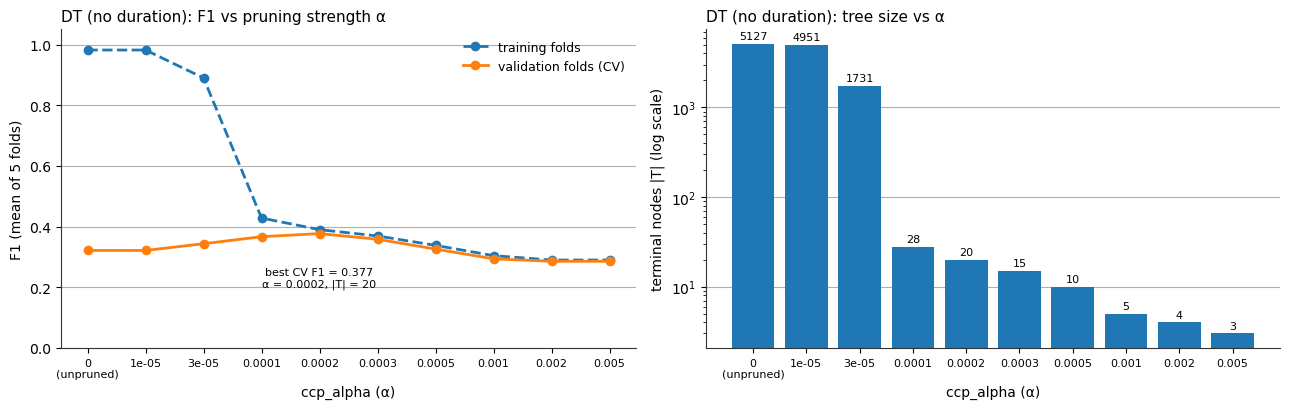

In [45]:
pruning_no_dur = pruning_curve(featurenoduration, "DT (no duration)")

In [46]:
dt_no_duration = fit_model("DT (no duration)",
                           DecisionTreeClassifier(random_state=RANDOM_STATE),
                           DT_GRID,
                           X_train[featurenoduration])
describe_selected_tree("DT (no duration)")

Fitting 5 folds for each of 360 candidates, totalling 1800 fits
[Trained & saved] DT (no duration)
Best parameters: {'ccp_alpha': 0.0, 'criterion': 'gini', 'max_depth': None, 'min_samples_leaf': 1, 'min_samples_split': 50}
CV f1: 0.3894 ± 0.0144
Selected tree: criterion = gini, depth = 28, terminal nodes |T| = 1140

Top 5 of 360 settings by mean CV f1:


,ccp_alpha,criterion,max_depth,min_samples_leaf,min_samples_split,mean CV f1,std
0,0.0,gini,None,1,50,0.3894,0.0144
1,0.0,gini,None,1,200,0.3892,0.0140
2,0.0,gini,15,1,200,0.3886,0.0134
3,0.0,gini,10,20,200,0.3877,0.0148
4,0.0,gini,None,20,200,0.3877,0.0148


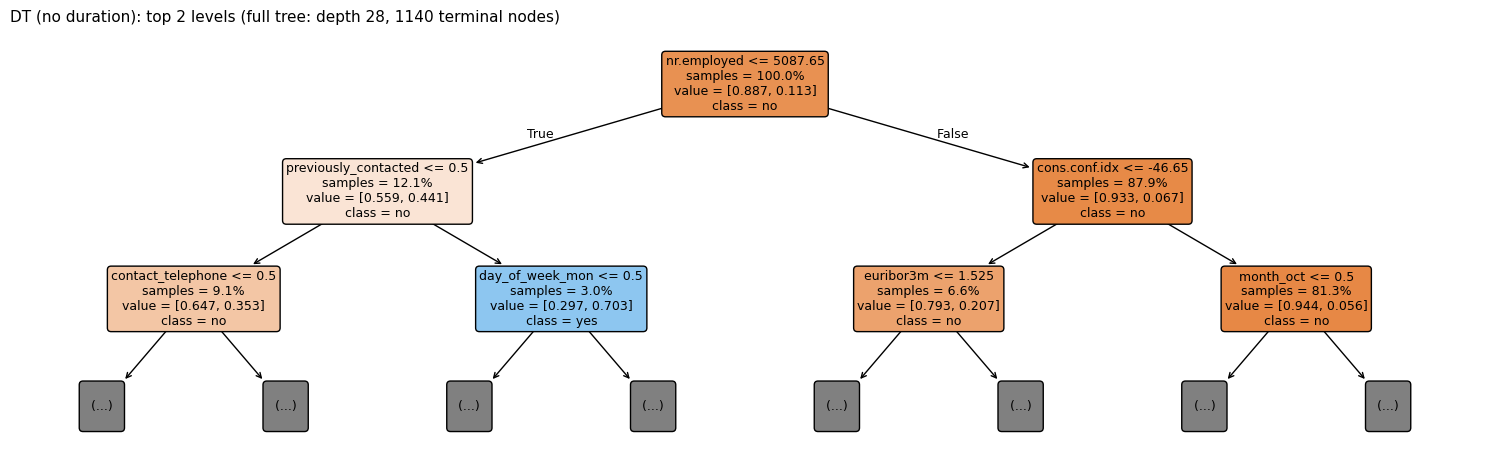

In [47]:
plot_top_of_tree("DT (no duration)")

### Model 3: Logistic Regression — with duration

Fitting 5 folds for each of 6 candidates, totalling 30 fits
[Trained & saved] LR (with duration)
Best parameters: {'C': 1}
CV f1: 0.5178 ± 0.0074


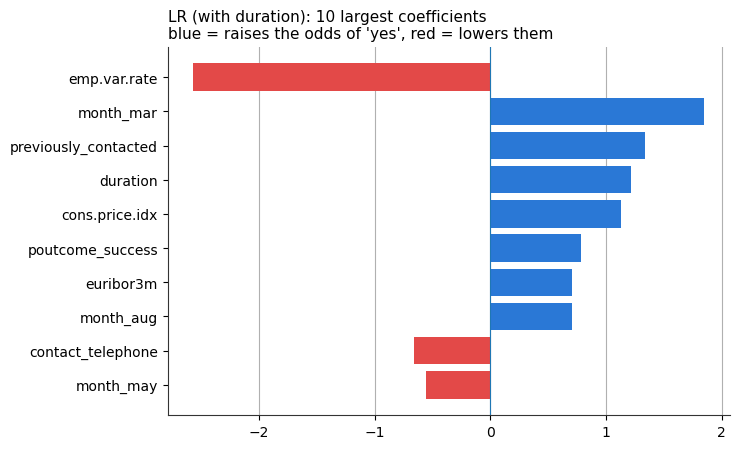

In [48]:
lr_with_duration = fit_model("LR (with duration)",
                             LogisticRegression(solver="lbfgs", max_iter=1000),
                             lr_grid,
                             X_train_scaled[featurewithduration])
plot_lr_coefficients("LR (with duration)")

### Model 4: Decision Tree with duration

,ccp_alpha,terminal nodes |T|,depth,train F1,CV F1,train accuracy,CV accuracy
0,0.00000,2437,27,1.0000,0.5198,1.0000,0.8891
1,0.00001,2437,27,1.0000,0.5198,1.0000,0.8891
2,0.00003,1739,27,0.9908,0.5252,0.9979,0.8917
3,0.00010,121,12,0.6911,0.5879,0.9339,0.9120
4,0.00020,29,8,0.6166,0.5963,0.9194,0.9155
5,0.00030,24,7,0.6044,0.5934,0.9176,0.9156
6,0.00050,17,6,0.6130,0.5993,0.9168,0.9141
7,0.00100,10,4,0.5864,0.5749,0.9142,0.9123
8,0.00200,7,3,0.5904,0.5864,0.9080,0.9073
9,0.00500,4,2,0.4906,0.4880,0.9030,0.9026


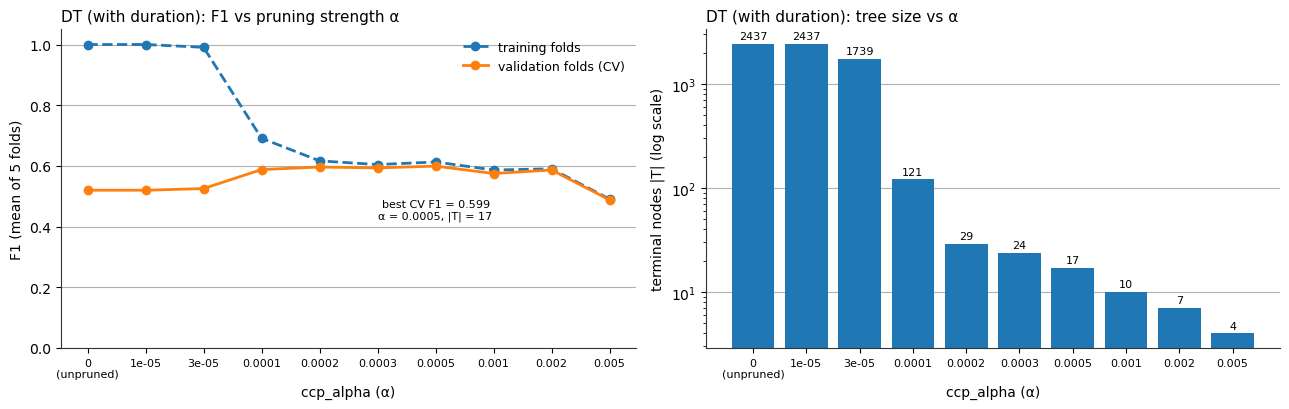

In [49]:
pruning_with_dur = pruning_curve(featurewithduration, "DT (with duration)")

Joint tuning of the key parameters with 5-fold and refit

In [50]:
dt_with_duration = fit_model("DT (with duration)",
                             DecisionTreeClassifier(random_state=RANDOM_STATE),
                             DT_GRID,
                             X_train[featurewithduration])
describe_selected_tree("DT (with duration)")

Fitting 5 folds for each of 360 candidates, totalling 1800 fits
[Trained & saved] DT (with duration)
Best parameters: {'ccp_alpha': 0.0003, 'criterion': 'entropy', 'max_depth': 10, 'min_samples_leaf': 1, 'min_samples_split': 2}
CV f1: 0.6003 ± 0.0099
Selected tree: criterion = entropy, depth = 10, terminal nodes |T| = 55

Top 5 of 360 settings by mean CV f1:


,ccp_alpha,criterion,max_depth,min_samples_leaf,min_samples_split,mean CV f1,std
0,0.0003,entropy,10,1,2,0.6003,0.0099
1,0.0003,entropy,None,1,2,0.6000,0.0096
2,0.0003,entropy,15,1,2,0.6000,0.0096
3,0.0003,entropy,None,20,2,0.5999,0.0102
4,0.0003,entropy,15,20,2,0.5999,0.0102


Top of the selected tree

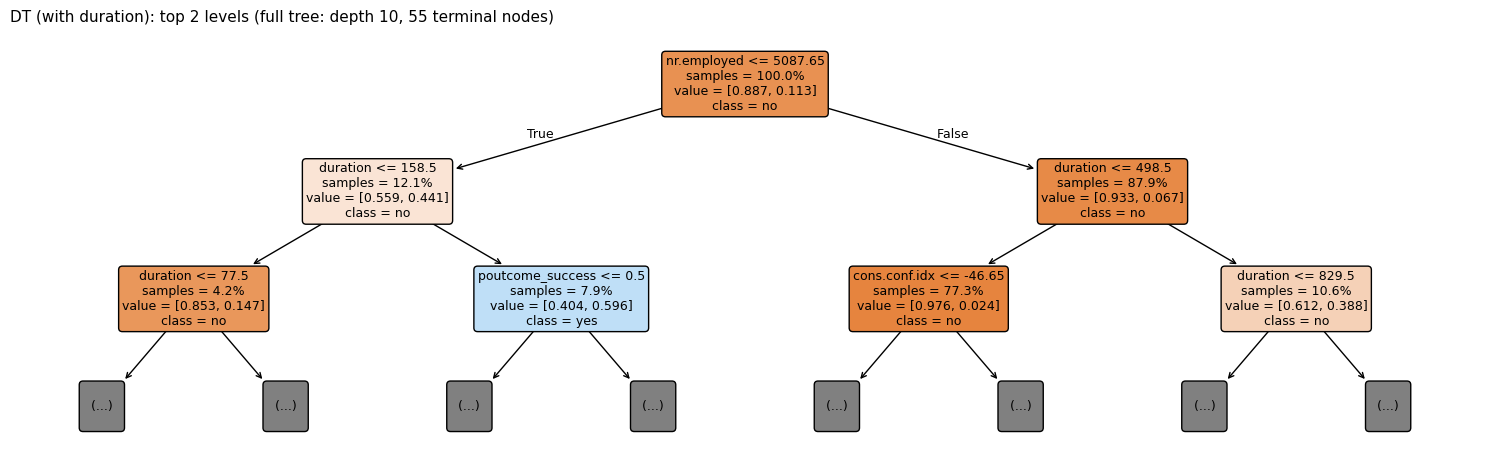

In [52]:
plot_top_of_tree("DT (with duration)")

important variables:

X_train: train feature	

y_train: train label	

X_test:	test feature	

y_test:	test label	

X_test：imput to model to let model predict

y_test：true reesult, used to compare with predicted result.

lr_no_duration: logistic model without duration

lr_with_duration: logistic model with duration 

dt_no_duration	: decision tree without duration

dt_with_duration: decision tree with duration.


In [53]:
# Save models
for name, grid in list(grids.items()):
    if name in MODEL_INPUTS:
        input_type, cols = MODEL_INPUTS[name]
        source = X_train_scaled if input_type == "scaled" else X_train
        save_grid(name, grid, source[cols])
        print("Saved:", name)

print("Saved outcome：", RUN_DIR)

Saved: LR (no duration)
Saved: DT (no duration)
Saved: LR (with duration)
Saved: DT (with duration)
Saved outcome： D:\Software\JupyterNotebooks\NTU\KM6312_GroupProject\bank-additional\Final\model_cache\02fd97b872b9d2d4b7384550c3b87592


## Support Vector Machine
## Random Forest
## Gradient Boosting

### Model 5 SVM without duration

In [54]:
from sklearn.svm import SVC
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

def make_svm(feature_cols):
    numeric_cols = [
        col for col in NUMERIC_COLS
        if col in feature_cols
    ]

    return Pipeline([
        ("preprocess", ColumnTransformer(
            transformers=[
                ("numeric", StandardScaler(), numeric_cols),
            ],
            remainder="passthrough",  # 保留 one-hot 和 binary 特征
        )),
        ("svc", SVC(
            kernel="rbf",
            class_weight="balanced",
            probability=False,
            cache_size=256,
            random_state=RANDOM_STATE,
        )),
    ])


svm_grid = {
    "svc__C": [0.1, 1, 10],
    "svc__gamma": ["scale"],
}

In [55]:
# Model 5: SVM without duration
svm_no_duration = fit_model(
    "SVM (no duration)",
    make_svm(featurenoduration),
    svm_grid,
    X_train[featurenoduration],
    n_jobs=2,
)

Fitting 5 folds for each of 3 candidates, totalling 15 fits
[Trained & saved] SVM (no duration)
Best parameters: {'svc__C': 1, 'svc__gamma': 'scale'}
CV f1: 0.4665 ± 0.0116


### Model 6 SVM with duration

In [56]:
# Model 6: SVM with duration
svm_with_duration = fit_model(
    "SVM (with duration)",
    make_svm(featurewithduration),
    svm_grid,
    X_train[featurewithduration],
    n_jobs=2,
)

Fitting 5 folds for each of 3 candidates, totalling 15 fits
[Trained & saved] SVM (with duration)
Best parameters: {'svc__C': 1, 'svc__gamma': 'scale'}
CV f1: 0.5773 ± 0.0080


In [57]:
def evaluate_svm(name, model, feature_cols):
    X_eval = X_test[feature_cols]

    y_pred = model.predict(X_eval)
    y_score = model.decision_function(X_eval)

    return {
        "model": name,
        "accuracy": metrics.accuracy_score(y_test, y_pred),
        "precision": metrics.precision_score(
            y_test, y_pred, zero_division=0
        ),
        "recall": metrics.recall_score(
            y_test, y_pred, zero_division=0
        ),
        "f1": metrics.f1_score(y_test, y_pred, zero_division=0),
        "roc_auc": metrics.roc_auc_score(y_test, y_score),
    }


svm_results = pd.DataFrame([
    evaluate_svm(
        "SVM (no duration)",
        svm_no_duration,
        featurenoduration,
    ),
    evaluate_svm(
        "SVM (with duration)",
        svm_with_duration,
        featurewithduration,
    ),
]).set_index("model")

display(svm_results.round(4))

svm_results.to_csv(RUN_DIR / "svm_test_results.csv")

,accuracy,precision,recall,f1,roc_auc
model,,,,,
SVM (no duration),0.8482,0.3935,0.6412,0.4877,0.7848
SVM (with duration),0.8543,0.4324,0.9375,0.5918,0.9384


### Model 7 RF without duration

In [58]:
from sklearn.ensemble import RandomForestClassifier

def make_rf():
    return RandomForestClassifier(
        n_estimators=200,
        max_features="sqrt",
        class_weight="balanced_subsample",
        random_state=RANDOM_STATE,
        n_jobs=1,  
    )

rf_grid = {
    "max_depth": [15, None],
    "min_samples_leaf": [1, 5],
}

In [59]:
# Model 7: Random Forest without duration
rf_no_duration = fit_model(
    "RF (no duration)",
    make_rf(),
    rf_grid,
    X_train[featurenoduration],
    n_jobs=2,
)

Fitting 5 folds for each of 4 candidates, totalling 20 fits
[Trained & saved] RF (no duration)
Best parameters: {'max_depth': None, 'min_samples_leaf': 5}
CV f1: 0.4963 ± 0.0123


### Model 8 RF with duration

In [60]:
# Model 8: Random Forest with duration
rf_with_duration = fit_model(
    "RF (with duration)",
    make_rf(),
    rf_grid,
    X_train[featurewithduration],
    n_jobs=2,
)

Fitting 5 folds for each of 4 candidates, totalling 20 fits
[Trained & saved] RF (with duration)
Best parameters: {'max_depth': 15, 'min_samples_leaf': 1}
CV f1: 0.6333 ± 0.0041


### Model 9 GB without duration

In [61]:
from sklearn.ensemble import GradientBoostingClassifier

# Use one-hot encoded data without standardization
def make_gb():
    return GradientBoostingClassifier(
        max_depth=2,
        random_state=RANDOM_STATE,
    )

# Per version: 4 configurations × 5 CV folds, followed by best-model refitting
gb_grid = {
    "n_estimators": [100, 200],
    "learning_rate": [0.05, 0.1],
}

In [62]:

# Model: Gradient Boosting without call duration
gb_no_duration = fit_model(
    "GB (no duration)",
    make_gb(),
    gb_grid,
    X_train[featurenoduration],
    n_jobs=2,
)

Fitting 5 folds for each of 4 candidates, totalling 20 fits
[Trained & saved] GB (no duration)
Best parameters: {'learning_rate': 0.1, 'n_estimators': 200}
CV f1: 0.3487 ± 0.0097


### Model 10 GB with duration

In [63]:
# Model: Gradient Boosting with call duration
gb_with_duration = fit_model(
    "GB (with duration)",
    make_gb(),
    gb_grid,
    X_train[featurewithduration],
    n_jobs=2,
)

Fitting 5 folds for each of 4 candidates, totalling 20 fits
[Trained & saved] GB (with duration)
Best parameters: {'learning_rate': 0.1, 'n_estimators': 200}
CV f1: 0.5689 ± 0.0072


In [64]:
# Inspect hyperparameter search results for both versions
for name in ["GB (no duration)", "GB (with duration)"]:
    search = grids[name]
    cv_results = pd.DataFrame(search.cv_results_)

    print(f"\n{name}")
    display(
        cv_results[[
            "param_n_estimators",
            "param_learning_rate",
            "mean_test_accuracy",
            "mean_test_precision",
            "mean_test_recall",
            "mean_test_f1",
            "mean_test_roc_auc",
            "std_test_f1",
        ]]
        .sort_values(
            by=f"mean_test_{REFIT_METRIC}",
            ascending=False,
        )
        .round(4)
    )

    print("Best parameters:", search.best_params_)
    print(f"Best CV {REFIT_METRIC}: {search.best_score_:.4f}")


GB (no duration)


,param_n_estimators,param_learning_rate,mean_test_accuracy,mean_test_precision,mean_test_recall,mean_test_f1,mean_test_roc_auc,std_test_f1
3,200,0.10,0.9008,0.6691,0.2358,0.3487,0.7956,0.0097
2,100,0.10,0.9005,0.6846,0.2169,0.3293,0.7936,0.0063
1,200,0.05,0.9005,0.6880,0.2142,0.3266,0.7934,0.0062
0,100,0.05,0.8998,0.7007,0.1943,0.3041,0.7910,0.0052


Best parameters: {'learning_rate': 0.1, 'n_estimators': 200}
Best CV f1: 0.3487

GB (with duration)


,param_n_estimators,param_learning_rate,mean_test_accuracy,mean_test_precision,mean_test_recall,mean_test_f1,mean_test_roc_auc,std_test_f1
3,200,0.10,0.9143,0.6567,0.5020,0.5689,0.9439,0.0072
2,100,0.10,0.9135,0.6591,0.4813,0.5562,0.9417,0.0046
1,200,0.05,0.9133,0.6588,0.4788,0.5544,0.9418,0.0058
0,100,0.05,0.9114,0.6645,0.4330,0.5241,0.9391,0.0086


Best parameters: {'learning_rate': 0.1, 'n_estimators': 200}
Best CV f1: 0.5689


# Evaluation

In [65]:

from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, average_precision_score,
                             confusion_matrix)
import pandas as pd

def evaluate(name, model, feature_cols, input_type, score_type):
    # input_type: LR use "scaled"(X_test_scaled)， others use "raw"(X_test)
    # score_type: SVM use decision_function，others use predict_proba
    X_eval = X_test_scaled[feature_cols] if input_type == "scaled" else X_test[feature_cols]
    y_pred = model.predict(X_eval)
    if score_type == "decision":
        y_score = model.decision_function(X_eval)
    else:
        pos = list(model.classes_).index(1)
        y_score = model.predict_proba(X_eval)[:, pos]
    tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
    return {
        "model": name,
        "accuracy": accuracy_score(y_test, y_pred),
        "precision": precision_score(y_test, y_pred, zero_division=0),
        "recall": recall_score(y_test, y_pred, zero_division=0),
        "f1": f1_score(y_test, y_pred, zero_division=0),
        "roc_auc": roc_auc_score(y_test, y_score),
        "pr_auc": average_precision_score(y_test, y_score),
        "TN": tn, "FP": fp, "FN": fn, "TP": tp,
    }

MODELS_TO_EVAL = [
    ("LR (no duration)",  lr_no_duration,  featurenoduration, "scaled", "proba"),
    ("LR (with duration)", lr_with_duration, featurewithduration, "scaled", "proba"),
    ("DT (no duration)",  dt_no_duration,  featurenoduration, "raw", "proba"),
    ("DT (with duration)", dt_with_duration, featurewithduration, "raw", "proba"),
    ("SVM (no duration)", svm_no_duration, featurenoduration, "raw", "decision"),
    ("SVM (with duration)", svm_with_duration, featurewithduration, "raw", "decision"),
    ("RF (no duration)",  rf_no_duration,  featurenoduration, "raw", "proba"),
    ("RF (with duration)", rf_with_duration, featurewithduration, "raw", "proba"),
    ("GB (no duration)",  gb_no_duration,  featurenoduration, "raw", "proba"),
    ("GB (with duration)", gb_with_duration, featurewithduration, "raw", "proba"),
]

results = pd.DataFrame([
    evaluate(name, model, cols, input_type, score_type)
    for name, model, cols, input_type, score_type in MODELS_TO_EVAL
]).set_index("model")

display(results.round(4))
results.round(4).to_csv("test_evaluation_results.csv")

# Compare each type of models
for family in ["LR", "DT", "SVM", "RF", "GB"]:
    f1_no = results.loc[f"{family} (no duration)", "f1"]
    f1_with = results.loc[f"{family} (with duration)", "f1"]
    print(f"{family}: F1-score: Model without duration {f1_no:.4f} ---- Model with duration {f1_with:.4f} "
          f"(Change: {f1_with - f1_no:+.4f})")

# Highest F1-score model withou duration
no_dur = results[[ "(no duration)" in idx for idx in results.index ]]
print("\nBest model without duration:", no_dur["f1"].idxmax(),
      "F1 =", round(no_dur["f1"].max(), 4))


,accuracy,precision,recall,f1,roc_auc,pr_auc,TN,FP,FN,TP
model,,,,,,,,,,
LR (no duration),0.8983,0.6480,0.2123,0.3198,0.8002,0.4535,7201,107,731,197
LR (with duration),0.9095,0.6507,0.4256,0.5147,0.9389,0.6008,7096,212,533,395
DT (no duration),0.8927,0.5415,0.3093,0.3937,0.7637,0.3705,7065,243,641,287
DT (with duration),0.9143,0.6225,0.6078,0.6150,0.9460,0.6293,6966,342,364,564
SVM (no duration),0.8482,0.3935,0.6412,0.4877,0.7848,0.3916,6391,917,333,595
SVM (with duration),0.8543,0.4324,0.9375,0.5918,0.9384,0.5678,6166,1142,58,870
RF (no duration),0.8725,0.4520,0.6196,0.5227,0.8045,0.4883,6611,697,353,575
RF (with duration),0.8980,0.5305,0.8254,0.6459,0.9461,0.6464,6630,678,162,766
GB (no duration),0.8983,0.6461,0.2144,0.3220,0.8096,0.4698,7199,109,729,199


LR: F1-score: Model without duration 0.3198 ---- Model with duration 0.5147 (Change: +0.1949)
DT: F1-score: Model without duration 0.3937 ---- Model with duration 0.6150 (Change: +0.2214)
SVM: F1-score: Model without duration 0.4877 ---- Model with duration 0.5918 (Change: +0.1041)
RF: F1-score: Model without duration 0.5227 ---- Model with duration 0.6459 (Change: +0.1231)
GB: F1-score: Model without duration 0.3220 ---- Model with duration 0.5730 (Change: +0.2510)

Best model without duration: RF (no duration) F1 = 0.5227
